# Drought severity from JRC/EDO's Soil Moisture Index

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/sources/jrc_edo_drought_index.ipynb) · [GitHub preview](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/sources/jrc_edo_drought_index.ipynb)

The European Drought Observatory (EDO) publishes the **Soil Moisture Index**
(SMI) every dekad (the 1st, 11th and 21st of each month) on a 5 km grid. SMI runs
from 0 (wilting point) to 1 (field capacity); lower is drier.

1. **Read** the native dekadal SMI for a patch of central Germany with crc-sdk's
   `EDO` provider. The dekads are irregular, so the SDK invents no fixed cadence.
2. **Reduce** each pixel's complete years to their annual minimum: the driest
   moment of the year.
3. **Fit** the annual minima explicitly (GEV by L-moments, Gumbel for minima as a
   fallback) and query **lower-tail** return periods: the 10-year value is the SMI
   reached or undercut once every 10 years on average.

Results describe the observed record, not a projection. The headless twin is
[`pipelines/jrc_drought_pipeline.py`](../../pipelines/jrc_drought_pipeline.py).
This notebook is heavy (one yearly file per year); `CRC_DOCS_CI=1` reads a
smaller box and ten years.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--pre",
                           "--disable-pip-version-check", "crc-sdk[netcdf]>=1.0.0a2,<2", "plotly>=6"])

from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import shapely
from crc_framework import DistributionFamily, SampleEstimator, SampleFit, Tail
from IPython.display import display

from crc_sdk import (EDO, Assets, Bounds, Cache, FitFailure, Period, Probability, Runtime,
                     Samples, Variable)

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"

DATA_DIR = Path("../data/jrc_edo_drought_index")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RUNTIME = Runtime(cache=Cache.reuse(DATA_DIR / "cache"))
CI = os.environ.get("CRC_DOCS_CI") == "1"
AREA = (Bounds(west=9.9, south=50.9, east=10.1, north=51.1) if CI
        else Bounds(west=9.5, south=50.5, east=10.5, north=51.5))
YEARS = (2015, 2024) if CI else (1995, 2024)
RETURN_PERIODS = [2, 5, 10, 25]
DESIGN_RETURN_PERIOD = 10

## 1. Read the dekadal observations

Every dekad of every pixel is one row, with the pixel's footprint. A dekad with
no value keeps its row with a null value.

169 pixels × 360 dekads, 0 without a value; release 3.0.1


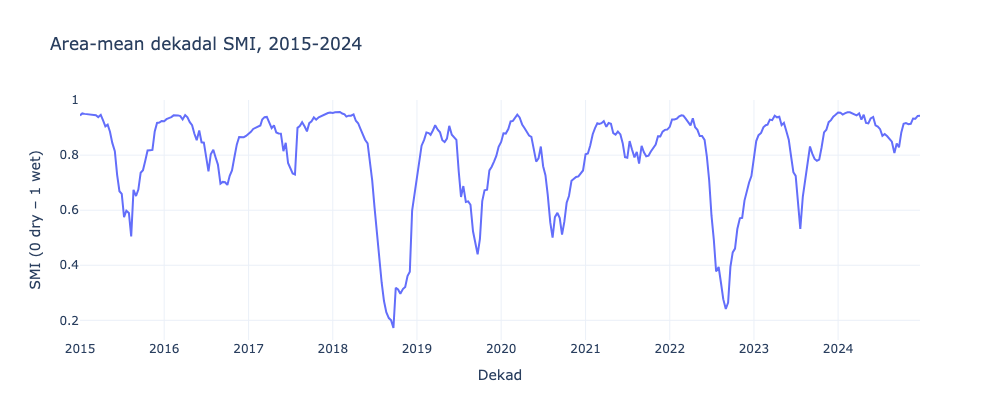

In [2]:
smi = EDO(product=EDO.Product.SOIL_MOISTURE_INDEX).select(area=AREA, time=Period.window(*YEARS))
observed = smi.write(DATA_DIR / "edo_smi_dekadal.parquet", overwrite=True, runtime=RUNTIME).read()
table = observed.table.to_pandas()
print(f"{table.support_id.nunique()} pixels × {table.time.nunique()} dekads, "
      f"{table.value.isna().sum()} without a value; release {observed.metadata.source.release.id}")
area_mean = table.groupby("time").value.mean()
fig = go.Figure(go.Scatter(x=pd.to_datetime(area_mean.index), y=area_mean.values, mode="lines"))
fig.update_layout(title=f"Area-mean dekadal SMI, {YEARS[0]}-{YEARS[1]}", xaxis_title="Dekad",
                  yaxis_title="SMI (0 dry – 1 wet)", width=1000, height=420)
fig.show()

## 2. Annual minima from complete years

A year enters only if all 36 dekads are observed; the driest dekad is its value.
`Samples.from_table` declares the result as annual samples with a **lower** tail.
Each pixel is represented by its centre point here.

In [3]:
table["year"] = table.time.str[:4].astype(int)
centres = (table.drop_duplicates("support_id").set_index("support_id").geometry
           .map(lambda wkb: shapely.from_wkb(wkb).centroid))
by_year = table.groupby(["support_id", "year"]).value.agg(["count", "min"]).reset_index()
complete = by_year[by_year["count"] == 36]
print(f"{len(complete)} complete pixel-years, {len(by_year) - len(complete)} incomplete left out")
minima = Samples.from_table(
    {"support_id": complete.support_id, "longitude": complete.support_id.map(lambda s: centres[s].x),
     "latitude": complete.support_id.map(lambda s: centres[s].y), "time": complete.year,
     "value": complete["min"]},
    variable=Variable("edo:annual_minimum_soil_moisture_index",
                      measurement=observed.metadata.spec.variables[0].measurement),
    probability=Probability.annual(tail=Tail.LOWER),
)

1690 complete pixel-years, 0 incomplete left out


## 3. Fit and query lower-tail return periods

Fitting is explicit. Pixels whose fit fails keep a failure record rather than an
invented curve. With ten (CI) or thirty annual values, long return periods are
extrapolations: a 25-year value can even fall below 0, outside the SMI range,
which signals an over-stretched fit rather than a forecast.

,pixels,median SMI,driest SMI
return period,,,
2.0,169,0.591,0.336
5.0,169,0.373,0.157
10.0,169,0.244,0.078
25.0,169,0.090,-0.018


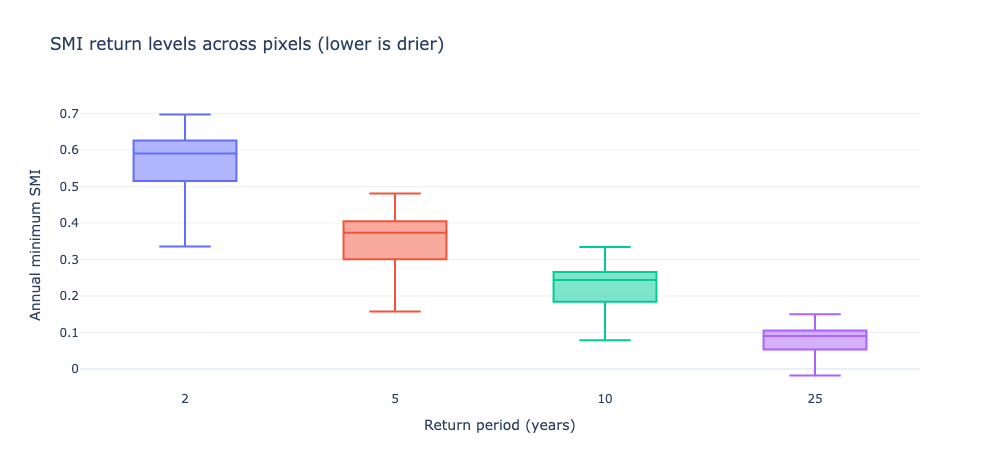

In [4]:
fit = SampleFit(family=DistributionFamily.GENERALIZED_EXTREME_VALUE, estimator=SampleEstimator.L_MOMENTS,
                minimum_samples=5,
                fallbacks=(SampleFit(family=DistributionFamily.GUMBEL_LEFT, minimum_samples=5),))
fitted = minima.fit(fit, on_failure=FitFailure.KEEP_NO_DATA)
pixels = sorted(complete.support_id.unique())
levels = fitted.evaluate(Assets({"pixel": pixels, "longitude": [centres[p].x for p in pixels],
                                 "latitude": [centres[p].y for p in pixels]}, id_column="pixel")
                        ).return_periods(RETURN_PERIODS).read().table.to_pandas()
summary = levels.groupby("query_value").value.agg(["count", "median", "min"]).rename(
    columns={"count": "pixels", "median": "median SMI", "min": "driest SMI"}).rename_axis("return period")
display(summary.round(3))

fig = go.Figure([
    go.Box(x=[f"{rp:g}" for rp in group.query_value], y=group.value, name=f"{rp:g}-year", boxpoints=False)
    for rp, group in levels.groupby("query_value")
])
fig.update_layout(title="SMI return levels across pixels (lower is drier)", showlegend=False,
                  xaxis_title="Return period (years)", yaxis_title="Annual minimum SMI", width=1000, height=470)
fig.show()

## Limits and reuse

- **Short records.** Thirty annual minima constrain a three-parameter GEV only
  loosely; treat 25-year values and beyond as indicative.
- **Model product.** SMI comes from the LISFLOOD hydrological model driven by
  observations, at 5 km; it is not a field measurement.
- **Stationarity.** The fit treats the record as one climate.

Headless:

```bash
uv run python pipelines/jrc_drought_pipeline.py --bounds 9.5 50.5 10.5 51.5 --years 1995 2024
```